# KMA/MSM – Přednáška 3: Simulování náhodných veličin

Notebook doprovází přednášku P03. Postupně projdeme:

1. zákon velkých čísel a Monte Carlo odhady,
2. generování pseudonáhodných čísel (lineární kongruentní generátor),
3. metodu inverzní transformace,
4. zamítací metodu (obecnou a s omezeným nosičem),
5. generování náhodných vektorů inverzní a zamítací metodou (i na neobdélníkové oblasti),
6. vícerozměrné normální rozdělení (Choleského rozklad) a Box-Mullerovu transformaci.

Každý oddíl obsahuje výpočet a ověření výsledku proti teorii (střední hodnoty, rozptyly, KS test, grafy).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # generátor PCG64 s pevným seedem -> reprodukovatelnost
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Zákon velkých čísel – Monte Carlo odhady

Je-li $X_1,\dots,X_n$ náhodný výběr a $\mathbb E|g(X)|<\infty$, pak
$\frac1n\sum_{i=1}^n g(X_i)\to \mathbb E\,g(X)$ skoro jistě.

Vyzkoušíme na $X\sim Exp(\lambda=\tfrac12)$, kde $\mathbb E X=2$, $\operatorname{var}X=4$,
$P(X\le 1)=1-e^{-1/2}$ a medián je $2\ln 2$.

In [2]:
n = 100_000
x = rng.exponential(scale=2.0, size=n)

print(f"E X      ~ {x.mean():.4f}   (teorie 2)")
print(f"var X    ~ {x.var():.4f}   (teorie 4)")
print(f"P(X<=1)  ~ {np.mean(x <= 1):.4f}   (teorie {1 - np.exp(-0.5):.4f})")
print(f"medián   ~ {np.median(x):.4f}   (teorie {2 * np.log(2):.4f})")

E X      ~ 2.0070   (teorie 2)
var X    ~ 4.0424   (teorie 4)
P(X<=1)  ~ 0.3928   (teorie 0.3935)
medián   ~ 1.3895   (teorie 1.3863)


Jak rychle se průměr blíží ke střední hodnotě? Směrodatná chyba průměru je $\sigma/\sqrt n$,
takže pro desetinásobné zpřesnění potřebujeme stokrát více simulací.

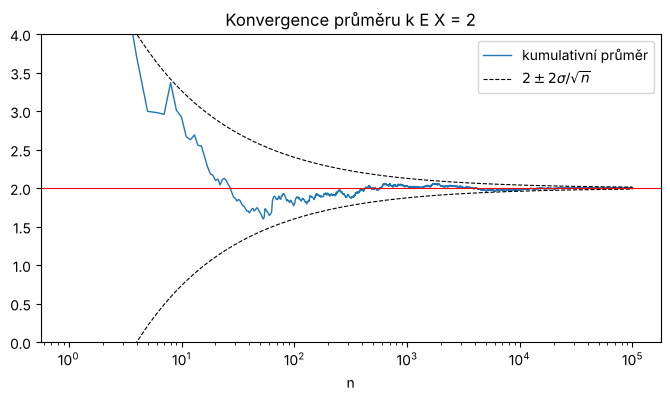

In [3]:
k = np.arange(1, n + 1)
prumery = np.cumsum(x) / k

plt.plot(k, prumery, lw=1, label="kumulativní průměr")
plt.plot(k, 2 + 2 * 2 / np.sqrt(k), "k--", lw=0.8, label=r"$2 \pm 2\sigma/\sqrt{n}$")
plt.plot(k, 2 - 2 * 2 / np.sqrt(k), "k--", lw=0.8)
plt.axhline(2, color="r", lw=0.8)
plt.xscale("log"); plt.ylim(0, 4); plt.xlabel("n"); plt.legend()
plt.title("Konvergence průměru k E X = 2")
plt.show()

## 2. Lineární kongruentní generátor

$x_i=(a x_{i-1}+c)\bmod m$, $u_i=x_i/m$. Generátor je deterministický – jde jen o to,
aby se posloupnost **chovala jako náhodná**. Následující implementace slouží jen pro ilustraci,
v praxi používáme knihovní generátory (PCG64, Mersenne Twister).

In [4]:
def lcg(n, seed=1, a=1103515245, c=12345, m=2**31):
    x = np.empty(n, dtype=np.int64)
    x_prev = seed
    for i in range(n):
        x_prev = (a * x_prev + c) % m
        x[i] = x_prev
    return x / m                      # u_i v intervalu <0,1)

u = lcg(10_000)
print(f"průměr  {u.mean():.4f}  (teorie 0.5)")
print(f"rozptyl {u.var():.4f}  (teorie {1/12:.4f})")
print(f"KS test rovnoměrnosti: p = {stats.kstest(u, 'uniform').pvalue:.3f}")

průměr  0.5025  (teorie 0.5)
rozptyl 0.0832  (teorie 0.0833)
KS test rovnoměrnosti: p = 0.375


Slabinou LCG je mřížková struktura: dvojice $(u_i,u_{i+1})$ leží na malém počtu přímek.
U malého modulu je to vidět okamžitě.

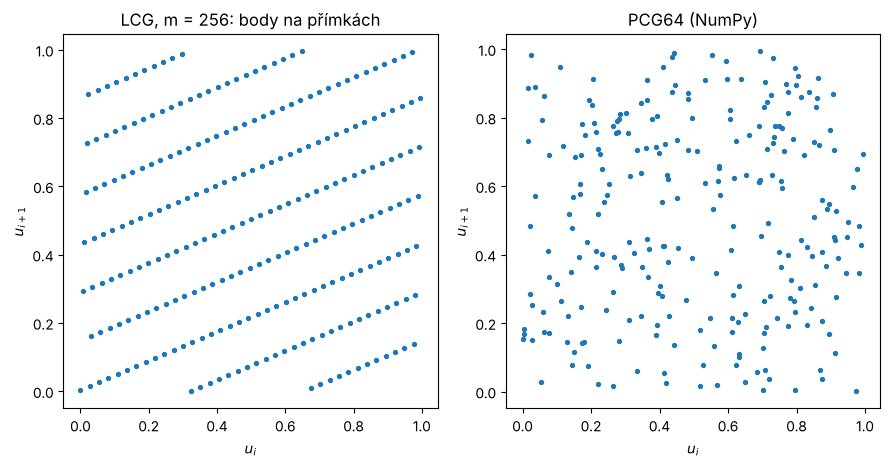

In [5]:
u_maly = lcg(256, seed=1, a=37, c=1, m=256)
u_dobry = rng.random(256)

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].scatter(u_maly[:-1], u_maly[1:], s=8)
ax[0].set_title("LCG, m = 256: body na přímkách")
ax[1].scatter(u_dobry[:-1], u_dobry[1:], s=8)
ax[1].set_title("PCG64 (NumPy)")
for a_ in ax:
    a_.set_xlabel(r"$u_i$"); a_.set_ylabel(r"$u_{i+1}$"); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

## 3. Metoda inverzní transformace

Je-li $U\sim R(0,1)$, pak $X=F^{-1}(U)$ má distribuční funkci $F$.

**Exponenciální rozdělení:** $F(x)=1-e^{-\lambda x}$, tedy $F^{-1}(u)=-\frac1\lambda\ln(1-u)$.

E X ~ 1.9956  (teorie 2.0)
KS test Exp: p = 0.330


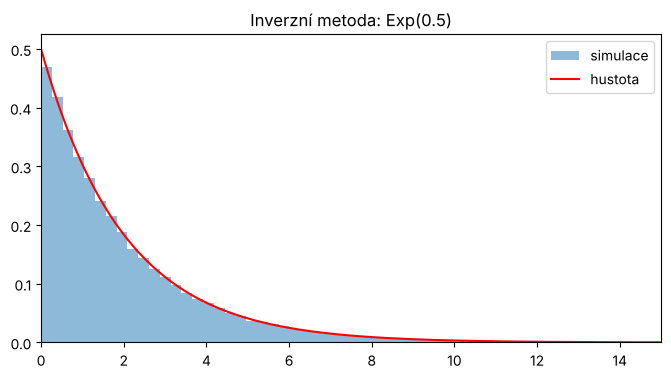

In [6]:
lam = 0.5
u = rng.random(n)
x = -np.log(1 - u) / lam              # F^{-1}(u)

print(f"E X ~ {x.mean():.4f}  (teorie {1/lam})")
print(f"KS test Exp: p = {stats.kstest(x, 'expon', args=(0, 1/lam)).pvalue:.3f}")

t = np.linspace(0, 15, 300)
plt.hist(x, bins=100, density=True, alpha=0.5, label="simulace")
plt.plot(t, lam * np.exp(-lam * t), "r", label="hustota")
plt.xlim(0, 15); plt.legend(); plt.title("Inverzní metoda: Exp(0.5)")
plt.show()

**Diskrétní veličina:** hodnoty $a_1<a_2<\dots$ s pravděpodobnostmi $p_j$.
Volíme $x=a_j$, kde $j$ je nejmenší index, pro který $u\le p_1+\dots+p_j$
(to dělá `np.searchsorted` nad kumulativními pravděpodobnostmi).

In [7]:
hodnoty = np.array([0, 1, 2, 3])
p = np.array([0.1, 0.4, 0.3, 0.2])

idx = np.searchsorted(np.cumsum(p), rng.random(n), side="right")
x_disc = hodnoty[idx]

print("relativní četnosti:", np.bincount(x_disc) / n)
print("teorie:            ", p)

relativní četnosti: [0.09972 0.40025 0.30005 0.19998]
teorie:             [0.1 0.4 0.3 0.2]


## 4. Zamítací metoda

Předpoklad: $f(x)\le c\,g(x)$, kde z hustoty $g$ umíme generovat.

1. kandidát $x$ z $g$,
2. $v\sim R(0,1)$,
3. přijmeme, pokud $v\le \dfrac{f(x)}{c\,g(x)}$.

Pravděpodobnost přijetí je $1/c$.

**Příklad:** $N(0,1)$ z Laplaceova rozdělení $g(x)=\frac12e^{-|x|}$.
Maximum podílu $f/g$ nastává v $|x|=1$, odtud $c=\sqrt{2e/\pi}\doteq1{,}32$.

In [8]:
c = np.sqrt(2 * np.e / np.pi)
m = 50_000

x = rng.laplace(size=m)                       # kandidáti z g
v = rng.random(m)
prijato = v <= stats.norm.pdf(x) / (c * stats.laplace.pdf(x))
z = x[prijato]

print(f"podíl přijatých {prijato.mean():.4f}  (teorie 1/c = {1/c:.4f})")
print(f"KS test normality: p = {stats.kstest(z, 'norm').pvalue:.3f}")

podíl přijatých 0.7609  (teorie 1/c = 0.7602)
KS test normality: p = 0.808


Geometricky: body $(x,\,v\cdot c\,g(x))$ jsou rovnoměrně rozložené pod křivkou $c\,g$;
přijmeme ty, které leží pod $f$.

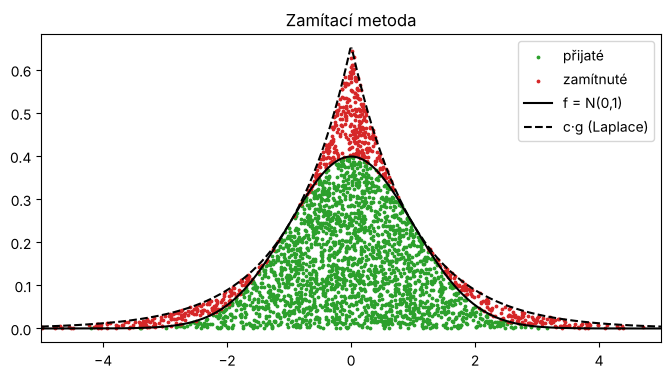

In [9]:
k = 3000
y_body = v[:k] * c * stats.laplace.pdf(x[:k])
t = np.linspace(-5, 5, 400)

plt.scatter(x[:k][prijato[:k]], y_body[prijato[:k]], s=3, c="tab:green", label="přijaté")
plt.scatter(x[:k][~prijato[:k]], y_body[~prijato[:k]], s=3, c="tab:red", label="zamítnuté")
plt.plot(t, stats.norm.pdf(t), "k", label="f = N(0,1)")
plt.plot(t, c * stats.laplace.pdf(t), "k--", label="c·g (Laplace)")
plt.xlim(-5, 5); plt.legend(); plt.title("Zamítací metoda")
plt.show()

### Zamítací metoda s omezeným nosičem

Hustota je nenulová jen na $(a,b)$ a $M=\max f$. Kandidáta generujeme rovnoměrně na $(a,b)$
a přijmeme, pokud $v\cdot M\le f(x)$. Pravděpodobnost přijetí je $\frac{1}{M(b-a)}$.

**Příklad:** $Beta(2,2)$, $f(x)=6x(1-x)$ na $(0,1)$, $M=f(\tfrac12)=1{,}5$.

podíl přijatých 0.6697  (teorie 1/(M(b-a)) = 0.6667)
KS test Beta(2,2): p = 0.464


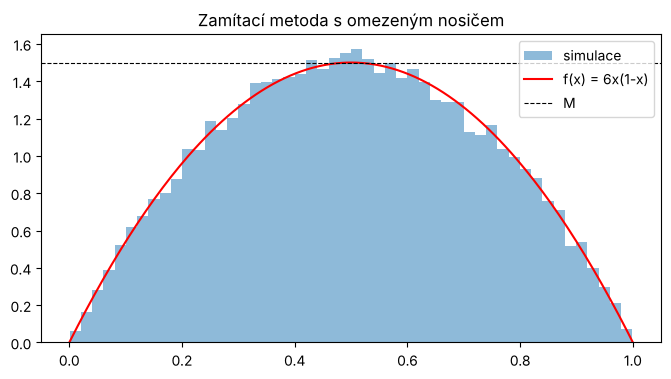

In [10]:
a, b, M = 0.0, 1.0, 1.5
u, v = rng.random(m), rng.random(m)
x = a + (b - a) * u
ok = v * M <= 6 * x * (1 - x)
x_beta = x[ok]

print(f"podíl přijatých {ok.mean():.4f}  (teorie 1/(M(b-a)) = {1/(M*(b-a)):.4f})")
print(f"KS test Beta(2,2): p = {stats.kstest(x_beta, 'beta', args=(2, 2)).pvalue:.3f}")

t = np.linspace(0, 1, 200)
plt.hist(x_beta, bins=50, density=True, alpha=0.5, label="simulace")
plt.plot(t, 6 * t * (1 - t), "r", label="f(x) = 6x(1-x)")
plt.axhline(M, color="k", ls="--", lw=0.8, label="M")
plt.legend(); plt.title("Zamítací metoda s omezeným nosičem")
plt.show()

## 5. Náhodné vektory

Použijeme hustotu z přednášky P01b:
$$f(x,y)=\tfrac16\left(\tfrac x2+\tfrac y3\right),\qquad x\in(0,2),\ y\in(0,3),$$
pro kterou platí $\mathbb E X=\frac76$, $\mathbb E Y=\frac74$, $\operatorname{cov}(X,Y)=-\frac1{24}$.

### Inverzní metoda

Rozklad $f(x,y)=f_X(x)\,f(y\,|\,x)$:

* $f_X(x)=\frac{x+1}{4}$, $F_X(x)=\frac{x^2+2x}{8}$, odkud $x=-1+\sqrt{1+8u}$,
* $F(y\,|\,x)=\dfrac{xy/3+y^2/9}{x+1}$, odkud $y=\dfrac{-3x+\sqrt{9x^2+36v(x+1)}}{2}$.

In [11]:
u, v = rng.random(n), rng.random(n)
x = -1 + np.sqrt(1 + 8 * u)                                   # F_X^{-1}(u)
y = (-3 * x + np.sqrt(9 * x**2 + 36 * v * (x + 1))) / 2       # F^{-1}(v | x)

print(f"E X ~ {x.mean():.4f}  (teorie {7/6:.4f})")
print(f"E Y ~ {y.mean():.4f}  (teorie {7/4:.4f})")
print(f"cov ~ {np.cov(x, y)[0, 1]:.4f}  (teorie {-1/24:.4f})")
x_inv, y_inv = x, y

E X ~ 1.1690  (teorie 1.1667)
E Y ~ 1.7513  (teorie 1.7500)
cov ~ -0.0411  (teorie -0.0417)


### Zamítací metoda

Oblast $A=(0,2)\times(0,3)$ má obsah $|A|=6$, maximum hustoty je $M=f(2,3)=\frac13$.
Generujeme body rovnoměrně v kvádru $A\times(0,M)$ a přijmeme ty pod plochou $f$.
Pravděpodobnost přijetí je $\frac{1}{M|A|}=\frac12$.

In [12]:
M = (2 / 2 + 3 / 3) / 6                 # maximum f v bodě (2,3)
x = rng.uniform(0, 2, m)
y = rng.uniform(0, 3, m)
w = rng.uniform(0, M, m)
ok = w <= (x / 2 + y / 3) / 6
x_rej, y_rej = x[ok], y[ok]

print(f"podíl přijatých {ok.mean():.4f}  (teorie 0.5)")
print(f"E X ~ {x_rej.mean():.4f},  E Y ~ {y_rej.mean():.4f},  cov ~ {np.cov(x_rej, y_rej)[0, 1]:.4f}")

podíl přijatých 0.4970  (teorie 0.5)
E X ~ 1.1689,  E Y ~ 1.7622,  cov ~ -0.0420


Obě metody dávají stejné rozdělení – porovnáme dvourozměrné histogramy.

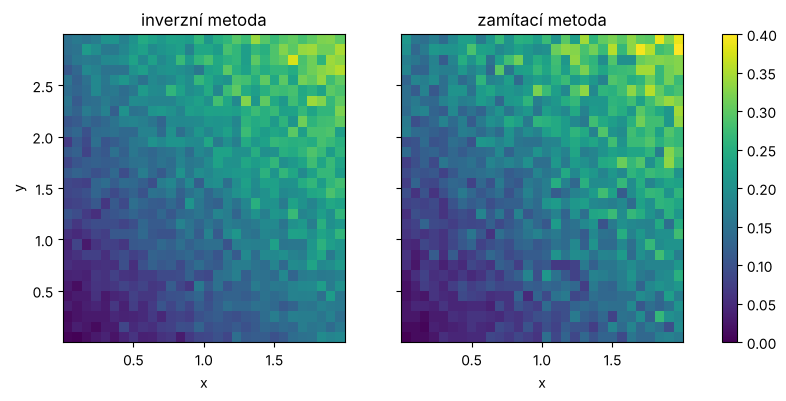

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].hist2d(x_inv[:m], y_inv[:m], bins=30, density=True, vmin=0, vmax=0.4)
ax[0].set_title("inverzní metoda")
h = ax[1].hist2d(x_rej, y_rej, bins=30, density=True, vmin=0, vmax=0.4)
ax[1].set_title("zamítací metoda")
for a_ in ax:
    a_.set_xlabel("x")
ax[0].set_ylabel("y")
fig.colorbar(h[3], ax=ax)
plt.show()

### Neobdélníková oblast: rovnoměrné rozdělení na trojúhelníku (cvičení, příklad 9)

Trojúhelník $T=\{(x,y):0<y<x<1\}$ má obsah $\frac12$, rovnoměrná hustota je tedy $f(x,y)=2$ na $T$.

* **Zamítání ze čtverce:** body $(U_1,U_2)$ ve čtverci $(0,1)^2$, přijmeme ty s $U_2<U_1$. Pravděpodobnost přijetí $\frac12$.
* **Inverzní metoda:** $f_X(x)=2x$, $F_X(x)=x^2$, tedy $x=\sqrt u$; $Y\,|\,X=x\sim R(0,x)$, tedy $y=x\,v$.
* **Seřazení:** $X=\max(U_1,U_2)$, $Y=\min(U_1,U_2)$ – bod pod úhlopříčkou zrcadlíme do $T$, nic se nezahazuje.

Teorie: $\mathbb E X=\frac23$, $\mathbb E Y=\frac13$, $\operatorname{cor}(X,Y)=\frac12$.

In [14]:
# a) zamítání ze čtverce
u1, u2 = rng.random(m), rng.random(m)
ok = u2 < u1
x_zam, y_zam = u1[ok], u2[ok]

# b) inverzní metoda
u, v = rng.random(m), rng.random(m)
x_inv3 = np.sqrt(u)
y_inv3 = x_inv3 * v

# c) seřazení dvojice
u1, u2 = rng.random(m), rng.random(m)
x_max, y_min = np.maximum(u1, u2), np.minimum(u1, u2)

print(f"podíl přijatých {ok.mean():.4f}  (teorie 0.5)")
for nazev, xx, yy in [("zamítání", x_zam, y_zam), ("inverze", x_inv3, y_inv3), ("max/min", x_max, y_min)]:
    print(f"{nazev:9s} E X ~ {xx.mean():.4f}, E Y ~ {yy.mean():.4f}, cor ~ {np.corrcoef(xx, yy)[0, 1]:.4f}")
print(f"teorie    E X = {2/3:.4f}, E Y = {1/3:.4f}, cor = 0.5")

podíl přijatých 0.4989  (teorie 0.5)
zamítání  E X ~ 0.6648, E Y ~ 0.3301, cor ~ 0.4961
inverze   E X ~ 0.6676, E Y ~ 0.3344, cor ~ 0.5029
max/min   E X ~ 0.6645, E Y ~ 0.3334, cor ~ 0.5037
teorie    E X = 0.6667, E Y = 0.3333, cor = 0.5


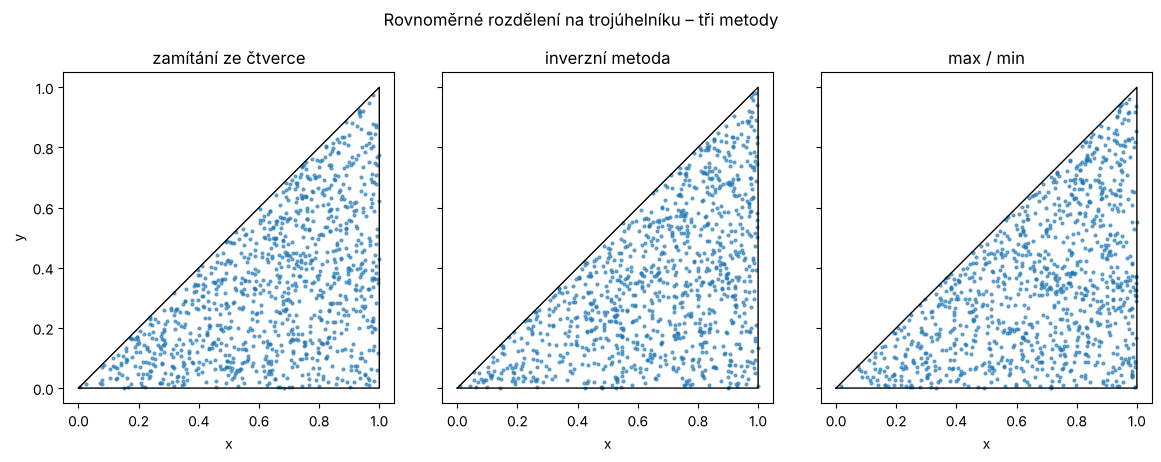

In [15]:
trojuhelnik = np.array([[0, 0], [1, 0], [1, 1], [0, 0]])
fig, ax = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for a_, (nazev, xx, yy) in zip(ax, [("zamítání ze čtverce", x_zam, y_zam),
                                    ("inverzní metoda", x_inv3, y_inv3),
                                    ("max / min", x_max, y_min)]):
    a_.scatter(xx[:1000], yy[:1000], s=4, alpha=0.6)
    a_.plot(trojuhelnik[:, 0], trojuhelnik[:, 1], "k", lw=1)
    a_.set_title(nazev); a_.set_xlabel("x"); a_.set_aspect("equal")
ax[0].set_ylabel("y")
plt.suptitle("Rovnoměrné rozdělení na trojúhelníku – tři metody", y=1.03)
plt.tight_layout(); plt.show()

### Neobdélníková oblast: nerovnoměrná hustota (cvičení, příklad 10)

Na stejném trojúhelníku $T$ uvažujeme hustotu
$$f(x,y)=c\,(2x+xy)=c\,x(2+y),\qquad c=\tfrac{24}{19}.$$

**Inverzní (podmíněná) metoda**

* $f_X(x)=c\left(2x^2+\frac{x^3}2\right)$, $F_X(x)=c\left(\frac23x^3+\frac18x^4\right)$ – polynom 4. stupně, rovnici $F_X(x)=u$ řešíme **numericky** (vektorizovaná bisekce),
* $F(y\,|\,x)=\dfrac{2y+y^2/2}{2x+x^2/2}$, odkud explicitně $y=-2+\sqrt{4+v(4x+x^2)}$.

**Zamítací metoda**

* ze čtverce $(0,1)^2$ s $M=\max f=f(1,1)=3c$: pravděpodobnost přijetí $\frac1{3c}=\frac{19}{72}\doteq0{,}264$,
* kandidáti rovnoměrně na $T$ (max/min, hustota $g=2$): $f\le\frac{3c}{2}g$, pravděpodobnost přijetí $\frac{19}{36}\doteq0{,}528$.

Teorie: $\mathbb E X=\frac{72}{95}\doteq0{,}758$, $\mathbb E Y=\frac25$, $\operatorname{cov}(X,Y)=\frac{28}{1425}\doteq0{,}0196$, $\operatorname{cor}(X,Y)\doteq0{,}418$.

In [16]:
c10 = 24 / 19
f10 = lambda x, y: c10 * x * (2 + y)            # hustota na T
F_X = lambda x: c10 * (2 * x**3 / 3 + x**4 / 8)  # marginální distribuční funkce

def F_X_inv(u, kroky=50):
    # vektorizovaná bisekce: F_X je rostoucí na (0,1)
    lo, hi = np.zeros_like(u), np.ones_like(u)
    for _ in range(kroky):
        mid = (lo + hi) / 2
        vlevo = F_X(mid) < u
        lo, hi = np.where(vlevo, mid, lo), np.where(vlevo, hi, mid)
    return (lo + hi) / 2

# inverzní metoda
u, v = rng.random(n), rng.random(n)
x10_inv = F_X_inv(u)
y10_inv = -2 + np.sqrt(4 + v * (4 * x10_inv + x10_inv**2))
print("kontrola u = v = 0.5:", F_X_inv(np.array([0.5]))[0].round(3), "(cvičení: x = 0.802)")

# zamítání ze čtverce
u1, u2, w = rng.random(m), rng.random(m), rng.uniform(0, 3 * c10, m)
ok_ctv = (u2 < u1) & (w <= f10(u1, u2))
x10_ctv, y10_ctv = u1[ok_ctv], u2[ok_ctv]

# zamítání s kandidáty rovnoměrně na T
u1, u2 = rng.random(m), rng.random(m)
xk, yk = np.maximum(u1, u2), np.minimum(u1, u2)
ok_T = rng.random(m) <= f10(xk, yk) / (3 * c10)        # f / (c g) = f / (3c/2 * 2)
x10_T, y10_T = xk[ok_T], yk[ok_T]

print(f"přijetí ze čtverce     {ok_ctv.mean():.4f}  (teorie {19/72:.4f})")
print(f"přijetí z trojúhelníku {ok_T.mean():.4f}  (teorie {19/36:.4f})")
for nazev, xx, yy in [("inverze", x10_inv, y10_inv), ("zam. čtverec", x10_ctv, y10_ctv), ("zam. T", x10_T, y10_T)]:
    print(f"{nazev:12s} E X ~ {xx.mean():.4f}, E Y ~ {yy.mean():.4f}, "
          f"cov ~ {np.cov(xx, yy)[0, 1]:.4f}, cor ~ {np.corrcoef(xx, yy)[0, 1]:.4f}")
print(f"teorie       E X = {72/95:.4f}, E Y = 0.4000, cov = {28/1425:.4f}, cor = 0.4184")

kontrola u = v = 0.5: 0.802 (cvičení: x = 0.802)
přijetí ze čtverce     0.2668  (teorie 0.2639)
přijetí z trojúhelníku 0.5279  (teorie 0.5278)
inverze      E X ~ 0.7589, E Y ~ 0.3999, cov ~ 0.0194, cor ~ 0.4162
zam. čtverec E X ~ 0.7603, E Y ~ 0.3995, cov ~ 0.0189, cor ~ 0.4050
zam. T       E X ~ 0.7574, E Y ~ 0.3962, cov ~ 0.0193, cor ~ 0.4115
teorie       E X = 0.7579, E Y = 0.4000, cov = 0.0196, cor = 0.4184


Body jsou hustší směrem k vrcholu $(1,1)$, kde je hustota největší. Vpravo je hustota $f$ na $T$ pro srovnání.

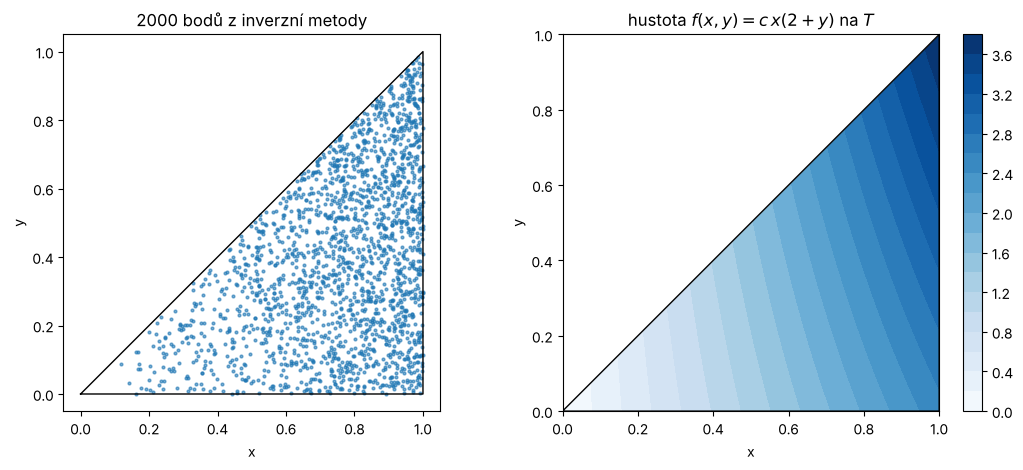

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
ax[0].scatter(x10_inv[:2000], y10_inv[:2000], s=4, alpha=0.6)
ax[0].plot(trojuhelnik[:, 0], trojuhelnik[:, 1], "k", lw=1)
ax[0].set_title("2000 bodů z inverzní metody")

gx, gy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
gf = np.where(gy < gx, f10(gx, gy), np.nan)
h = ax[1].contourf(gx, gy, gf, levels=20, cmap="Blues")
ax[1].plot(trojuhelnik[:, 0], trojuhelnik[:, 1], "k", lw=1)
ax[1].set_title(r"hustota $f(x,y)=c\,x(2+y)$ na $T$")
fig.colorbar(h, ax=ax[1])
for a_ in ax:
    a_.set_xlabel("x"); a_.set_ylabel("y"); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

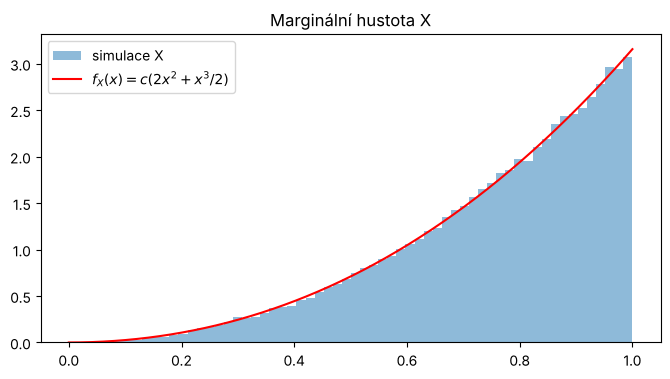

In [18]:
# marginální rozdělení X: histogram vs. f_X
t = np.linspace(0, 1, 200)
plt.hist(x10_inv, bins=60, density=True, alpha=0.5, label="simulace X")
plt.plot(t, c10 * (2 * t**2 + t**3 / 2), "r", label=r"$f_X(x)=c(2x^2+x^3/2)$")
plt.legend(); plt.title("Marginální hustota X"); plt.show()

## 6. Vícerozměrné normální rozdělení

Je-li $\mathbf Z\sim N_k(\mathbf 0,\mathbf I)$ a $\boldsymbol\Sigma=\mathbf L\mathbf L^T$ (Choleského rozklad),
pak $\mathbf X=\boldsymbol\mu+\mathbf L\mathbf Z\sim N_k(\boldsymbol\mu,\boldsymbol\Sigma)$.

Použijeme parametry z přednášky P02b: $\boldsymbol\mu=(3,2)^T$, $\boldsymbol\Sigma=\begin{pmatrix}10&5\\5&5\end{pmatrix}$.

In [19]:
mu = np.array([3.0, 2.0])
Sigma = np.array([[10.0, 5.0], [5.0, 5.0]])

L = np.linalg.cholesky(Sigma)           # Sigma = L L^T
print("L =\n", L)

Z = rng.standard_normal((n, 2))         # Z ~ N_2(0, I)
X = mu + Z @ L.T                        # X = mu + L Z (řádkově)

print("výběrový průměr:", X.mean(axis=0))
print("výběrová kovarianční matice:\n", np.cov(X, rowvar=False))

L =
 [[3.16227766 0.        ]
 [1.58113883 1.58113883]]
výběrový průměr: [2.99708835 2.00122514]
výběrová kovarianční matice:
 [[10.01433381  5.01832093]
 [ 5.01832093  5.02457846]]


Vrstevnice hustoty jsou elipsy. Elipsa $(\mathbf x-\boldsymbol\mu)^T\boldsymbol\Sigma^{-1}(\mathbf x-\boldsymbol\mu)=\chi^2_2(0{,}95)$
by měla obsahovat přibližně 95 % bodů (vlastnost 3 z P02b).

podíl bodů uvnitř 95% elipsy: 0.9498


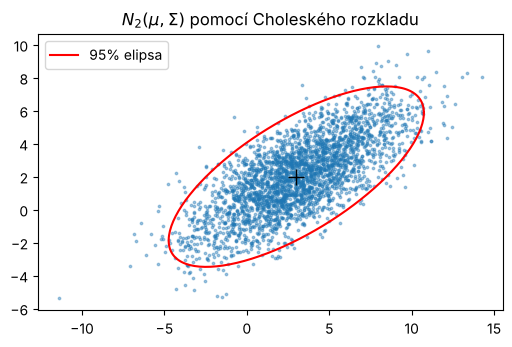

In [20]:
q = stats.chi2.ppf(0.95, df=2)
D2 = np.einsum("ij,jk,ik->i", X - mu, np.linalg.inv(Sigma), X - mu)   # Mahalanobisova vzdálenost^2
print(f"podíl bodů uvnitř 95% elipsy: {np.mean(D2 <= q):.4f}")

phi = np.linspace(0, 2 * np.pi, 200)
elipsa = mu + np.sqrt(q) * np.column_stack([np.cos(phi), np.sin(phi)]) @ L.T

plt.figure(figsize=(6, 6))
plt.scatter(X[:3000, 0], X[:3000, 1], s=3, alpha=0.4)
plt.plot(elipsa[:, 0], elipsa[:, 1], "r", label="95% elipsa")
plt.plot(*mu, "k+", ms=12)
plt.gca().set_aspect("equal"); plt.legend()
plt.title(r"$N_2(\mu, \Sigma)$ pomocí Choleského rozkladu")
plt.show()

Totéž přímo knihovní funkcí:

In [21]:
X2 = rng.multivariate_normal(mu, Sigma, size=n)
print(np.cov(X2, rowvar=False))

[[9.95096309 4.96423684]
 [4.96423684 4.95746669]]


### Box-Mullerova transformace

Jsou-li $U_1,U_2\sim R(0,1)$ nezávislé, pak
$Z_1=\sqrt{-2\ln U_1}\cos(2\pi U_2)$ a $Z_2=\sqrt{-2\ln U_1}\sin(2\pi U_2)$
jsou nezávislé $N(0,1)$.

In [22]:
u1, u2 = rng.random(n), rng.random(n)
r = np.sqrt(-2 * np.log(u1))
z1, z2 = r * np.cos(2 * np.pi * u2), r * np.sin(2 * np.pi * u2)

print(f"průměr {z1.mean():.4f}, rozptyl {z1.var():.4f}, cor(z1, z2) = {np.corrcoef(z1, z2)[0, 1]:.4f}")
print(f"KS test normality: p = {stats.kstest(z1, 'norm').pvalue:.3f}")

průměr -0.0001, rozptyl 0.9961, cor(z1, z2) = 0.0068
KS test normality: p = 0.527


## Úlohy na procvičení

1. Inverzní metodou generujte z Weibullova rozdělení $F(x)=1-e^{-(x/\lambda)^k}$ a ověřte střední hodnotu $\lambda\,\Gamma(1+1/k)$.
2. Zamítací metodou generujte z hustoty $f(x)=\frac{3}{2}x^2$ na $(-1,1)$. Jaký je podíl přijatých bodů?
3. Pomocí P02a generujte dvourozměrné Poissonovo rozdělení s $\mathbb E X_1=4$, $\mathbb E X_2=9$, $\rho=0{,}5$ a ověřte korelaci.
4. Generujte Marshall-Olkinovo rozdělení přes $X=\min(U_1,U_3)$, $Y=\min(U_2,U_3)$ a ověřte $\rho=\frac{\gamma}{\alpha+\beta+\gamma}$ i $P(X=Y)$.